# EDA Menfess PENS (Agustus – Oktober 2026)
Notebook ini untuk **Data Collection & EDA** proyek analisis sentimen fasilitas kampus PENS.

**Prinsip yang dipakai**
- Kolom `Text` asli **tidak diubah** (aman untuk semua model nanti).
- Pembersihan teks untuk EDA disimpan di kolom terpisah `text_eda` (khusus visualisasi).
- Preprocessing untuk pemodelan dibuat terpisah per model, bukan di notebook ini.

## 0. Import Library

In [2]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
WARNA, WARNA2 = "#3B7DD8", "#E8743B"
HARI_ORDER = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

## 1. Load Data
Pastikan ketiga file CSV berada di folder yang sama dengan notebook ini.

In [3]:
df_agu = pd.read_csv("telegram_menfess_agustus.csv")
df_sep = pd.read_csv("telegram_menfess_september.csv")
df_okt = pd.read_csv("telegram_menfess_oktober.csv")

# tandai asal bulan tiap data
df_agu["bulan_sumber"] = "Agustus"
df_sep["bulan_sumber"] = "September"
df_okt["bulan_sumber"] = "Oktober"
BULAN_ORDER = ["Agustus", "September", "Oktober"]

print("Agustus  :", df_agu.shape)
print("September:", df_sep.shape)
print("Oktober  :", df_okt.shape)

Agustus  : (1466, 7)
September: (2078, 7)
Oktober  : (1263, 7)


In [4]:
# gabungkan ketiga data
df = pd.concat([df_agu, df_sep, df_okt], ignore_index=True)
print("Gabungan :", df.shape)
df.head()

Gabungan : (4807, 7)


,Message_ID,Type,Sender_ID,Username,Date_WIB,Text,bulan_sumber
0,9530,Main_Post,-1001647181983,pensfess,2026-08-31 23:37:04,Info kost kost an cowo under 750 yg jarak nya ...,Agustus
1,9529,Main_Post,-1001647181983,pensfess,2026-08-31 22:57:19,Sender punya bisnis yang Alhamdulillah lolos p...,Agustus
2,9528,Main_Post,-1001647181983,pensfess,2026-08-31 22:54:49,"Ara CE maba, sumpah arek e lucu maneh, gak coc...",Agustus
3,9527,Main_Post,-1001647181983,pensfess,2026-08-31 22:53:57,Ada yang jual sepatu futsal gak?,Agustus
4,9526,Main_Post,-1001647181983,pensfess,2026-08-31 22:01:30,"infoin dong oprec DPM kapan ya, sistem pemilih...",Agustus


## 2. Gambaran Awal Data

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4807 entries, 0 to 4806
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Message_ID    4807 non-null   int64 
 1   Type          4807 non-null   object
 2   Sender_ID     4807 non-null   int64 
 3   Username      4807 non-null   object
 4   Date_WIB      4807 non-null   object
 5   Text          4807 non-null   object
 6   bulan_sumber  4807 non-null   object
dtypes: int64(2), object(5)
memory usage: 263.0+ KB


In [6]:
print("Missing value per kolom:")
print(df.isna().sum())
print()
print("Jumlah nilai unik per kolom:")
print(df.nunique())

Missing value per kolom:
Message_ID      0
Type            0
Sender_ID       0
Username        0
Date_WIB        0
Text            0
bulan_sumber    0
dtype: int64

Jumlah nilai unik per kolom:
Message_ID      4807
Type               1
Sender_ID          1
Username           1
Date_WIB        4805
Text            4802
bulan_sumber       3
dtype: int64


Kolom yang nilainya sama di semua baris (mis. `Type`, `Sender_ID`, `Username`) tidak informatif, jadi dibuang.

## 3. Cleaning Ringan (tanpa mengubah isi `Text`)

In [7]:
# a) buang kolom konstan
kolom_konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan yang dibuang:", kolom_konstan)
df = df.drop(columns=kolom_konstan)

Kolom konstan yang dibuang: ['Type', 'Sender_ID', 'Username']


In [8]:
# b) buang duplikat (teks persis sama)
n_awal = len(df)
df = df.drop_duplicates(subset="Text", keep="first").reset_index(drop=True)
print(f"Duplikat dibuang: {n_awal - len(df)} baris")

# c) buang teks kosong / terlalu pendek
df["Text"] = df["Text"].astype(str)
df = df[df["Text"].str.strip().str.len() >= 5].reset_index(drop=True)
print("Sisa data:", len(df), "baris")

Duplikat dibuang: 5 baris
Sisa data: 4802 baris


In [9]:
# d) datetime + fitur waktu
df["Date_WIB"] = pd.to_datetime(df["Date_WIB"])
df = df.sort_values("Date_WIB").reset_index(drop=True)

df["tanggal"] = df["Date_WIB"].dt.date
df["jam"] = df["Date_WIB"].dt.hour
df["hari"] = df["Date_WIB"].dt.dayofweek.map(dict(enumerate(HARI_ORDER)))

# e) fitur panjang teks (dari Text asli)
df["n_karakter"] = df["Text"].str.len()
df["n_kata"] = df["Text"].str.split().str.len()

df[["n_karakter", "n_kata"]].describe().round(1)

,n_karakter,n_kata
count,4802.0,4802.0
mean,100.4,16.9
std,54.5,8.9
min,29.0,1.0
25%,57.0,10.0
50%,87.0,15.0
75%,132.0,22.0
max,240.0,49.0


## 4. Visualisasi Dasar: Volume & Waktu
### 4.1 Jumlah post per bulan

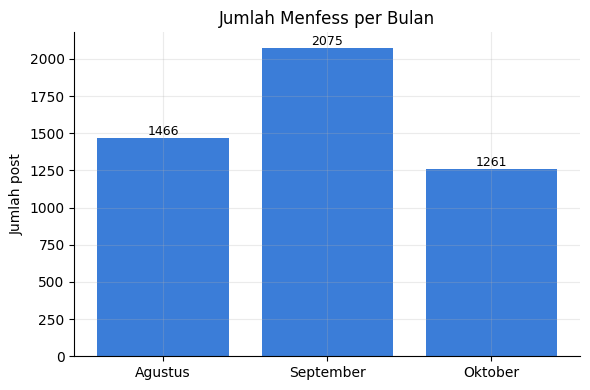

In [10]:
per_bulan = df["bulan_sumber"].value_counts().reindex(BULAN_ORDER)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(per_bulan.index, per_bulan.values, color=WARNA)
ax.bar_label(bars, fontsize=9)
ax.set_title("Jumlah Menfess per Bulan")
ax.set_ylabel("Jumlah post")
plt.tight_layout()
plt.show()

### 4.2 Tren jumlah post per hari

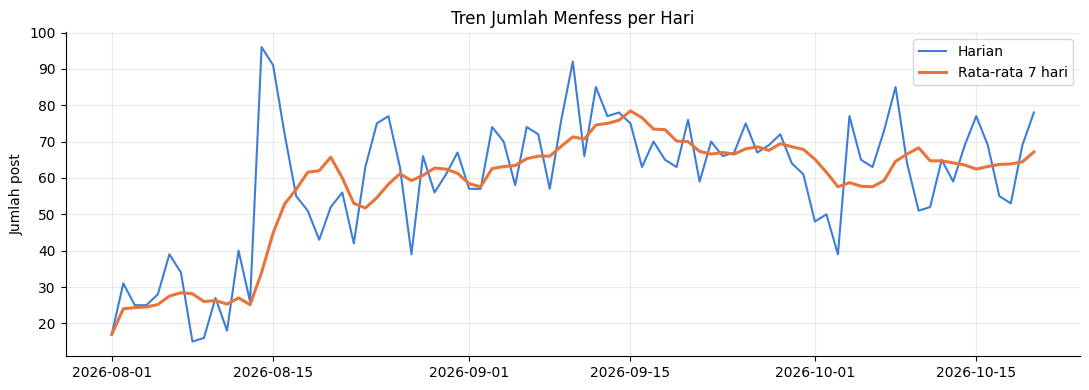

In [11]:
per_hari = df.groupby("tanggal").size()
per_hari.index = pd.to_datetime(per_hari.index)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(per_hari.index, per_hari.values, color=WARNA, lw=1.5, label="Harian")
ax.plot(per_hari.index, per_hari.rolling(7, min_periods=1).mean(),
        color=WARNA2, lw=2.2, label="Rata-rata 7 hari")
ax.set_title("Tren Jumlah Menfess per Hari")
ax.set_ylabel("Jumlah post")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3 Distribusi post per jam

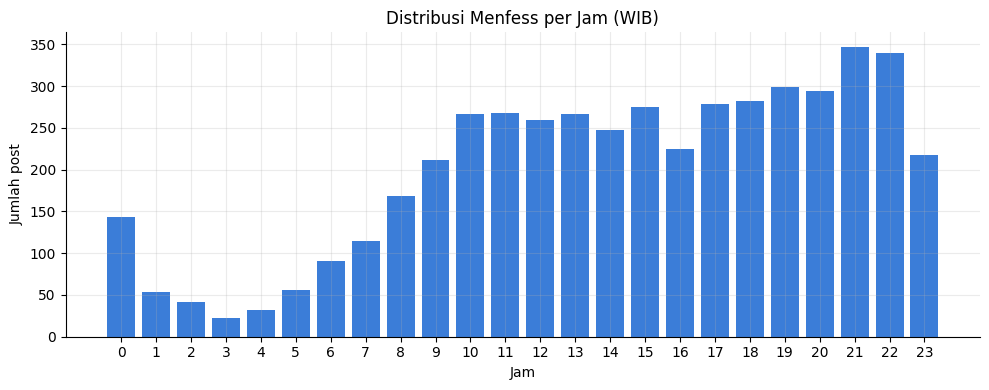

In [12]:
per_jam = df["jam"].value_counts().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(per_jam.index, per_jam.values, color=WARNA)
ax.set_xticks(range(24))
ax.set_title("Distribusi Menfess per Jam (WIB)")
ax.set_xlabel("Jam")
ax.set_ylabel("Jumlah post")
plt.tight_layout()
plt.show()

### 4.4 Heatmap aktivitas: hari × jam

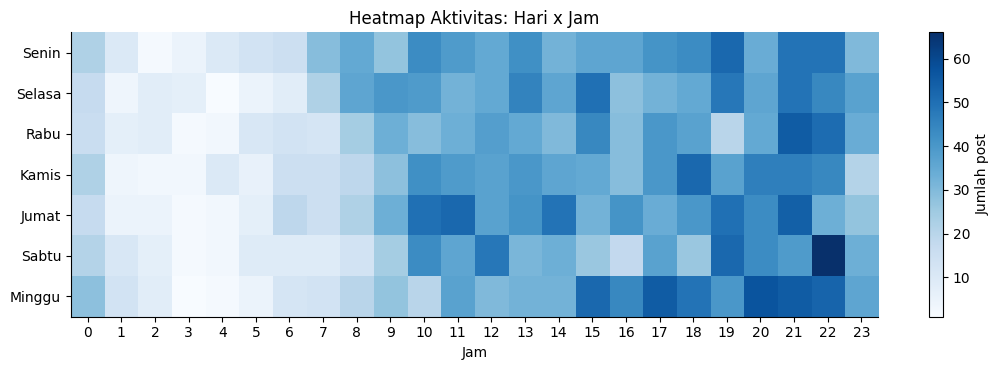

In [13]:
pivot = (df.groupby(["hari", "jam"]).size().unstack(fill_value=0)
           .reindex(index=HARI_ORDER, columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(pivot.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(24))
ax.set_yticks(range(len(HARI_ORDER)))
ax.set_yticklabels(HARI_ORDER)
ax.set_xlabel("Jam")
ax.set_title("Heatmap Aktivitas: Hari x Jam")
ax.grid(False)
plt.colorbar(im, ax=ax, label="Jumlah post")
plt.tight_layout()
plt.show()

### 4.5 Distribusi panjang teks

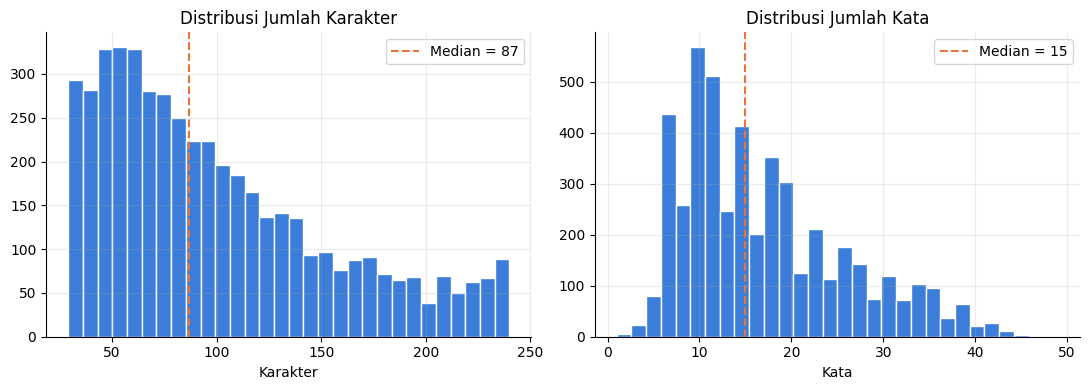

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["n_karakter"], bins=30, color=WARNA, edgecolor="white")
axes[0].axvline(df["n_karakter"].median(), color=WARNA2, ls="--",
                label=f"Median = {df['n_karakter'].median():.0f}")
axes[0].set_title("Distribusi Jumlah Karakter")
axes[0].set_xlabel("Karakter")
axes[0].legend()

axes[1].hist(df["n_kata"], bins=30, color=WARNA, edgecolor="white")
axes[1].axvline(df["n_kata"].median(), color=WARNA2, ls="--",
                label=f"Median = {df['n_kata'].median():.0f}")
axes[1].set_title("Distribusi Jumlah Kata")
axes[1].set_xlabel("Kata")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Text EDA (`text_eda`)
Versi bersih **sementara** hanya untuk visualisasi kata. Kolom `Text` asli tetap utuh.

In [15]:
STOPWORDS = set("""
yang dan di ke dari ini itu untuk dengan pada adalah atau juga karena kalau kalo
jadi dalam akan sudah udah belum lagi bisa ada aja saja sih deh dong nih lah kok kan
yg dg dgn utk dr krn tp tapi tpi tau tahu mau pengen ingin bgt banget sangat
ga gak nggak ngga engga enggak tidak tak bukan nya ya yaa yah yak ye
aku saya gue gw gua kamu kmu kalian kita kami dia mereka sender
apa apakah siapa kapan dimana mana gimana bagaimana kenapa mengapa berapa
sama se lebih paling masih cuma cuman hanya sekali kali lagi terus trs
sih si pas lalu abis habis setelah sebelum saat waktu kemarin tadi besok
dulu nanti sekarang skrg hari ini
boleh minta tolong mohon info infoin infokan infokn thanks makasih
terima kasih terimakasih makasi tq thx
punya pernah sering selalu kadang cukup
mas mbak kak kakak bang bro sis gaes guys teman temen
dm reply menfess pens pensfess
buat rek kah kira gitu pake kayak kaya jangan tanya orang cara
""".split())

URL_RE      = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE  = re.compile(r"[@#]\w+")
NONALPHA_RE = re.compile(r"[^a-z\s]")
REPEAT_RE   = re.compile(r"(.)\1{2,}")   # bangetttt -> banget


def bersihkan_eda(teks):
    t = teks.lower()
    t = URL_RE.sub(" ", t)
    t = MENTION_RE.sub(" ", t)
    t = NONALPHA_RE.sub(" ", t)       # emoji, angka, tanda baca dibuang
    t = REPEAT_RE.sub(r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


def tokenisasi_eda(teks_bersih):
    return [w for w in teks_bersih.split() if w not in STOPWORDS and len(w) > 2]


df["text_eda"] = df["Text"].apply(bersihkan_eda)
df["tokens"] = df["text_eda"].apply(tokenisasi_eda)

df[["Text", "text_eda"]].head(8)

,Text,text_eda
0,"Sender ga paham nih yang lagi rame sekarang , ...",sender ga paham nih yang lagi rame sekarang to...
1,apa ada yg tau tempat latihan atau komunitas a...,apa ada yg tau tempat latihan atau komunitas a...
2,disini adakah mahasiswa GT angkatan 21? Sender...,disini adakah mahasiswa gt angkatan sender mau...
3,guys adakah info catering harian gitu yg bisa ...,guys adakah info catering harian gitu yg bisa ...
4,"Barusan sender liat porseni, dan peringkat pen...",barusan sender liat porseni dan peringkat pens...
5,Kok perasaan sender kek kurang ya template pkk...,kok perasaan sender kek kurang ya template pkk...
6,"hai, adakah yg nonton sod sendirian disini??",hai adakah yg nonton sod sendirian disini
7,"Noh yang dari maren ngomongin tg gada update, ...",noh yang dari maren ngomongin tg gada update b...


### 5.1 Bag of Words: Top 20 kata (unigram)

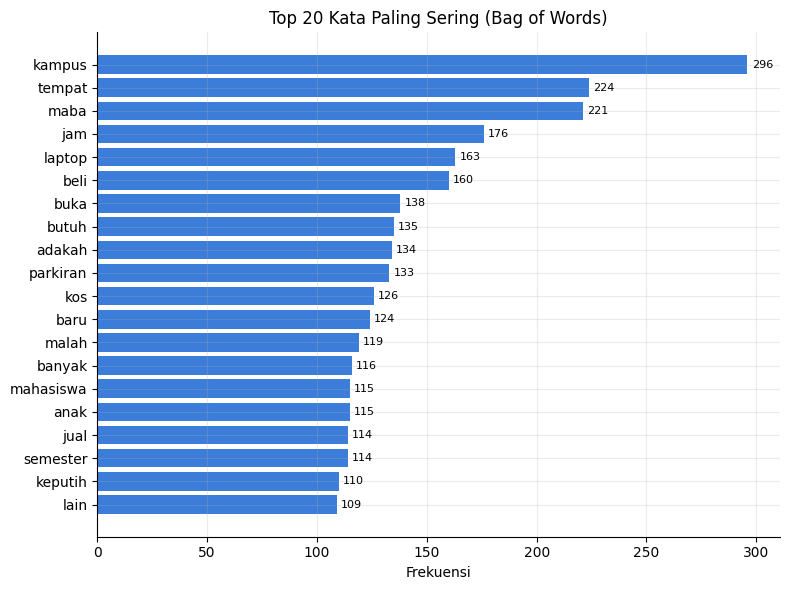

In [16]:
semua_token = [t for toks in df["tokens"] for t in toks]
top_uni = Counter(semua_token).most_common(20)
kata, frek = zip(*top_uni)

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(kata[::-1], frek[::-1], color=WARNA)
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_title("Top 20 Kata Paling Sering (Bag of Words)")
ax.set_xlabel("Frekuensi")
plt.tight_layout()
plt.show()

### 5.2 Top 15 bigram (pasangan kata)

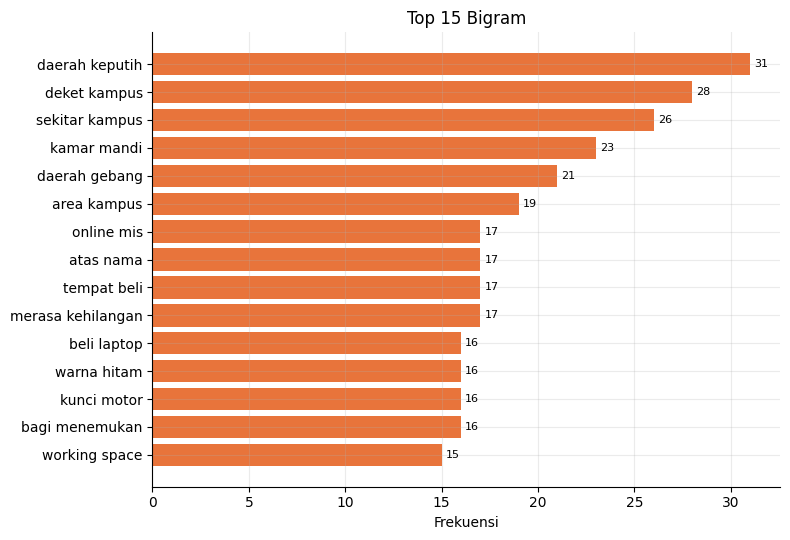

In [17]:
bigram = Counter()
for toks in df["tokens"]:
    bigram.update(zip(toks, toks[1:]))

top_bi = [(" ".join(b), c) for b, c in bigram.most_common(15)]
kata, frek = zip(*top_bi)

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(kata[::-1], frek[::-1], color=WARNA2)
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_title("Top 15 Bigram")
ax.set_xlabel("Frekuensi")
plt.tight_layout()
plt.show()

### 5.3 Word cloud (opsional)
Butuh `pip install wordcloud`. Kalau belum terpasang, sel ini hanya menampilkan info.

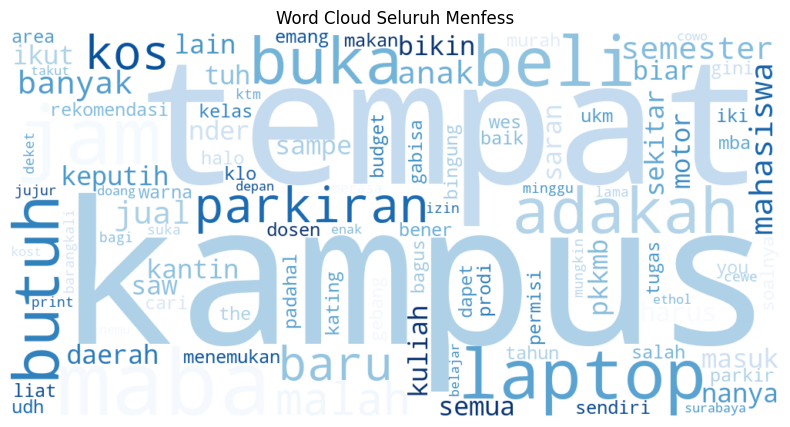

In [18]:
try:
    from wordcloud import WordCloud
    wc = WordCloud(width=1000, height=500, background_color="white",
                   colormap="Blues", max_words=100
                   ).generate_from_frequencies(Counter(semua_token))
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud Seluruh Menfess")
    plt.show()
except ImportError:
    print("wordcloud belum terpasang -> jalankan: pip install wordcloud")

## 6. Flag Topik Fasilitas
Keyword di bawah masih **versi awal** (berbasis regex). Perlu dicek manual dan diperluas bersama tim.

In [19]:
KATEGORI_FASILITAS = {
    "Parkir":             r"\bparkir\w*|\bgembok\w*",
    "Musholla/Masjid":    r"\bmusho?lla\w*|\bmasjid\w*|\bwudhu\w*|\bwudu\w*",
    "Kantin/Makanan":     r"\bkantin\w*|\bkafetaria\b",
    "Toilet/KM":          r"\btoilet\w*|\bkamar mandi\b|\bwc\b|\bkm\b",
    "Lift/Tangga":        r"\blift\w*|\belevator\b|\btangga\b",
    "AC/Kelistrikan":     r"\bac\b|\bpendingin\b|\bkipas\b|\blampu\b|\blistrik mati\b",
    "WiFi/Internet":      r"\bwi-?fi\b|\binternet\b|\bhotspot\b|\bsinyal\b",
    "Gedung/Ruang/Kelas": r"\bgedung\w*|\bruang(?:an)?\b|\bkelas\b|\blantai\b|\blt ?\d+|\bsaw\b",
    "Lab/Perpustakaan":   r"\blab\b|\blaboratorium\b|\bperpus\w*",
    "Olahraga/Lapangan":  r"\blapangan\b|\bgym\b|\bgor\b|\bkolam\b",
    "Akses/Keamanan":     r"\bsmart ?card\b|\bgerbang\b|\bsatpam\b|\bportal\b",
}

teks_lower = df["Text"].str.lower()
for kat, pola in KATEGORI_FASILITAS.items():
    df["fas_" + kat] = teks_lower.str.contains(pola, regex=True)

kolom_fas = ["fas_" + k for k in KATEGORI_FASILITAS]
df["relevan_fasilitas"] = df[kolom_fas].any(axis=1)

n_rel = int(df["relevan_fasilitas"].sum())
print(f"Post terkait fasilitas: {n_rel} ({n_rel / len(df) * 100:.1f}% dari {len(df)})")

Post terkait fasilitas: 763 (15.9% dari 4802)


### 6.1 Proporsi post terkait fasilitas

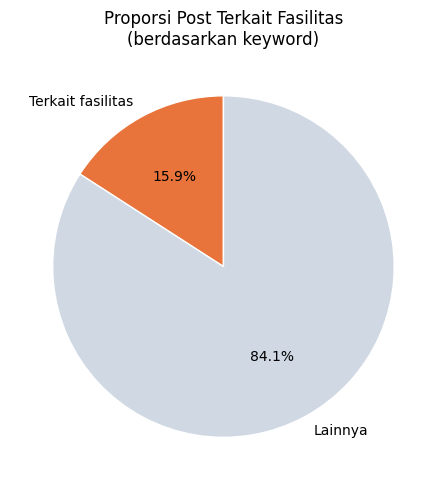

In [20]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie([n_rel, len(df) - n_rel], labels=["Terkait fasilitas", "Lainnya"],
       autopct="%1.1f%%", colors=[WARNA2, "#CFD8E3"], startangle=90,
       wedgeprops={"edgecolor": "white"})
ax.set_title("Proporsi Post Terkait Fasilitas\n(berdasarkan keyword)")
plt.tight_layout()
plt.show()

### 6.2 Jumlah post per kategori fasilitas

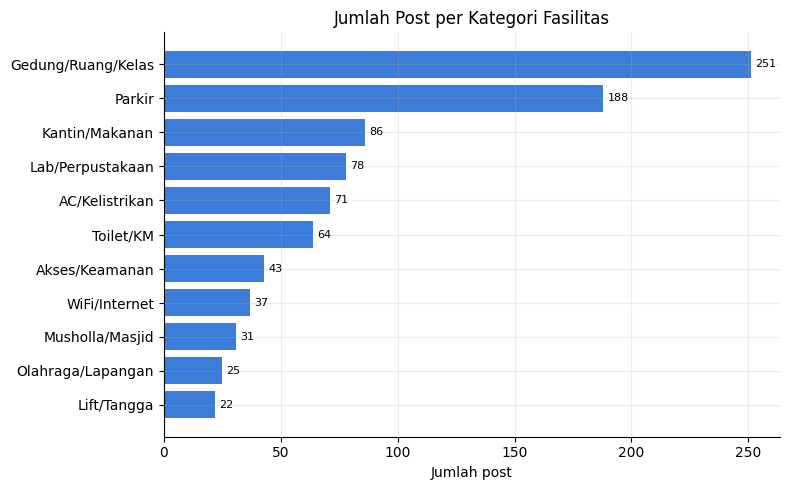

In [21]:
jumlah_kat = pd.Series({k: int(df["fas_" + k].sum()) for k in KATEGORI_FASILITAS}).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(jumlah_kat.index, jumlah_kat.values, color=WARNA)
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_title("Jumlah Post per Kategori Fasilitas")
ax.set_xlabel("Jumlah post")
plt.tight_layout()
plt.show()

### 6.3 Kategori fasilitas per bulan

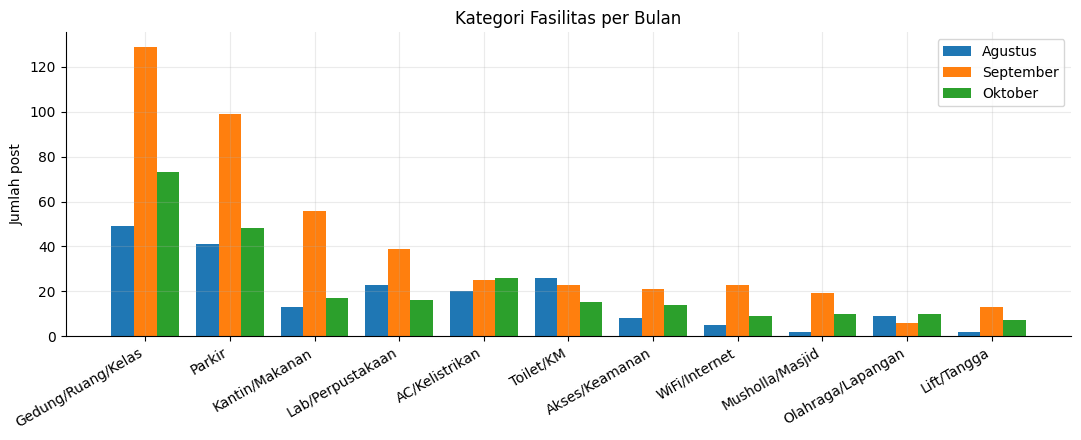

,Gedung/Ruang/Kelas,Parkir,Kantin/Makanan,Lab/Perpustakaan,AC/Kelistrikan,Toilet/KM,Akses/Keamanan,WiFi/Internet,Musholla/Masjid,Olahraga/Lapangan,Lift/Tangga
bulan_sumber,,,,,,,,,,,
Agustus,49,41,13,23,20,26,8,5,2,9,2
September,129,99,56,39,25,23,21,23,19,6,13
Oktober,73,48,17,16,26,15,14,9,10,10,7


In [22]:
tab = pd.DataFrame({k: df.groupby("bulan_sumber")["fas_" + k].sum()
                    for k in KATEGORI_FASILITAS}).reindex(BULAN_ORDER)
tab = tab[tab.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(tab.columns))
lebar = 0.8 / len(tab)
for i, bln in enumerate(tab.index):
    ax.bar(x + i * lebar, tab.loc[bln].values, lebar, label=bln)
ax.set_xticks(x + lebar * (len(tab) - 1) / 2)
ax.set_xticklabels(tab.columns, rotation=30, ha="right")
ax.set_title("Kategori Fasilitas per Bulan")
ax.set_ylabel("Jumlah post")
ax.legend()
plt.tight_layout()
plt.show()

tab

### 6.4 Top kata pada post terkait fasilitas

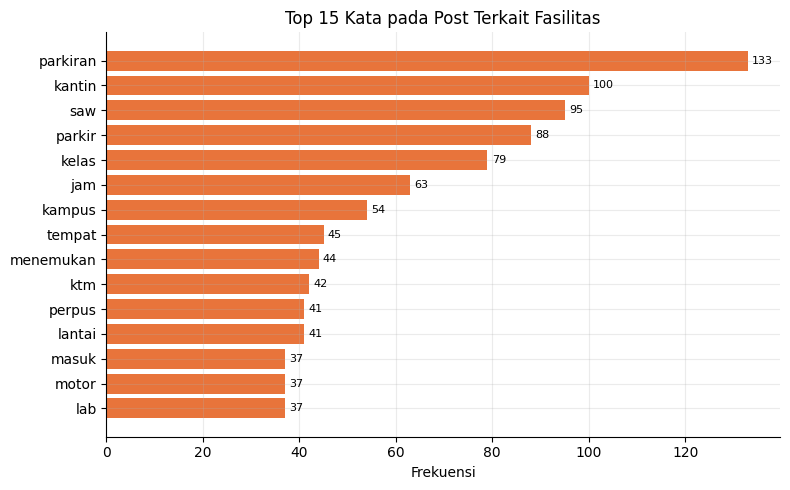

In [23]:
tok_fas = [t for toks in df.loc[df["relevan_fasilitas"], "tokens"] for t in toks]
kata, frek = zip(*Counter(tok_fas).most_common(15))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(kata[::-1], frek[::-1], color=WARNA2)
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_title("Top 15 Kata pada Post Terkait Fasilitas")
ax.set_xlabel("Frekuensi")
plt.tight_layout()
plt.show()

## 7. Cek Manual Keyword
Lihat sampel post untuk mencari **false positive** (terdeteksi fasilitas padahal bukan) dan **false negative** (fasilitas tapi tidak terdeteksi), lalu perbaiki `KATEGORI_FASILITAS`.

In [24]:
pd.set_option("display.max_colwidth", 200)

print("=== SAMPEL: TERDETEKSI FASILITAS (cek false positive) ===")
df[df["relevan_fasilitas"]].sample(15, random_state=42)[["Text"]]

=== SAMPEL: TERDETEKSI FASILITAS (cek false positive) ===


,Text
2556,Ada yg kehilangan HP di area lorong D3 dekat lab JJ-106? Hapenya sekarang di satpam depan. Tadi ditemukan sama bu CS
1943,"kk samsung tumbler ungu sdt a yg kmrn tumblernya menggelengar di kelas, tolong jangan fufufufu 🤥🤥"
4723,Di kantin yang jual geprek tapi sambel nya sambel terasi ga ya
1551,"saw 701 ini wangi ya, ga ada bau kaki ga ada bau kaus kaki juga. nyaman deh disana, ga perlu pake fresh care"
2422,"Buat yg pecahin visor helmku rsv sv 300 parkir ktm, helmku mari diapakno sampe rusak visore? ditunggu baiknya"
3836,yang nemu charger LAPTOP lenovo hitam di SAW-06.09 last seen hari senin kemarim minta tolong
4753,Ini kantin pustika tutup ta? Pesenan sender di app foodlab kok gak di acc
1229,ada yang tau tempat sewa alat kebutuhan industri atau sewa lab uji di Surabaya?
952,apakah besok siangan dikit susah cari parkir?
1667,Kantin kalo siang macetnya dah kek parkiran njir


In [25]:
print("=== SAMPEL: TIDAK TERDETEKSI (cek false negative) ===")
df[~df["relevan_fasilitas"]].sample(15, random_state=42)[["Text"]]

=== SAMPEL: TIDAK TERDETEKSI (cek false negative) ===


,Text
3711,"Guys, badan ikan sender kayak bengkak gitu, sepertinya dropsy / sisik nanas, sender kudu gimana plis😭"
159,info dong tempat persewaan kamera yang trusted ada dimana
2347,"aku iki kek ono info sing viral"" nang PENS talah rek, mosok wes dadi mahasiswa akhir ra ngrrti opo opo aku iki"
2882,"minta link form pens attendance terbaru dong rek, makasi"
3779,"buat temenku. aku cuman mau bilang. masih banyak ikan di luar sana, jangan hanya terpaku pada satu ikan"
2587,gmna pendapat kalian tentang seorang agnostik?
2856,"Sender punya hp baterai nya boros sangattt\nTempat trusted buat servise dimana ya, atau kakak"" ada yg buka jasa infokan sender ya"
3463,I love you....\nI want you....\nI need you....\nDi dalam benakku...
3020,"Buat yang pernah makai foodlab, semisal menu nya ternyata habis, itu bakalan ditolak terus refund atau udah dikasih tau duluan kalau menu nya habis?"
3984,"nderrr, anak TRM26 ada yg cowo ntikk kahh?? aku kek pernah liat anak TRM26 ada yg kyk cowoo ntikk woww😋"


## 8. Simpan Hasil

In [26]:
simpan_kolom = ["Message_ID", "bulan_sumber", "Date_WIB", "Text", "text_eda",
                "n_karakter", "n_kata", "relevan_fasilitas"] + kolom_fas
df[simpan_kolom].to_csv("data_eda.csv", index=False)

df[df["relevan_fasilitas"]].sample(50, random_state=42)[["Text"]].to_csv("sampel_cek_relevan.csv", index=False)
df[~df["relevan_fasilitas"]].sample(50, random_state=42)[["Text"]].to_csv("sampel_cek_tidak_relevan.csv", index=False)

print("Tersimpan: data_eda.csv, sampel_cek_relevan.csv, sampel_cek_tidak_relevan.csv")

Tersimpan: data_eda.csv, sampel_cek_relevan.csv, sampel_cek_tidak_relevan.csv


## 9. Catatan Temuan (isi sendiri setelah EDA)
- Volume data per bulan: …
- Jam / hari paling ramai: …
- Kategori fasilitas paling banyak dibahas: …
- Masalah kualitas data (slang, bahasa Jawa, sarkasme, noise jual-beli/kos): …
- Perbaikan keyword yang diperlukan: …